In [202]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from utils import wasserstein

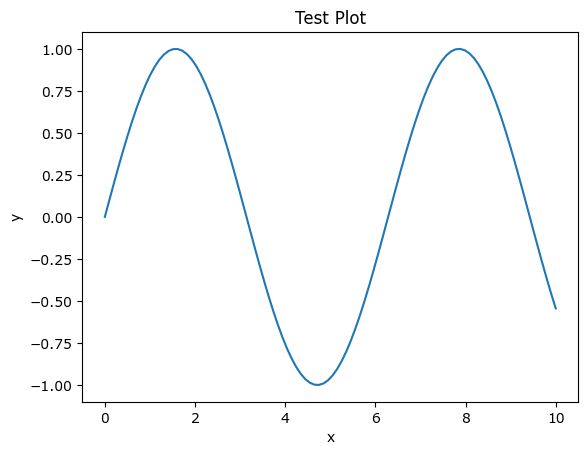

In [ ]:
def test():
    x = np.linspace(0, 10, 100)
    y = np.sin(x)
    plt.plot(x, y)
    plt.xlabel('x')
    plt.ylabel('y')
    plt.title('Test Plot')
    plt.show()

test()

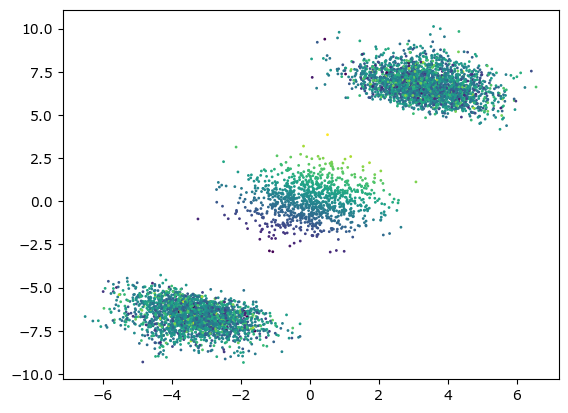

In [ ]:
import random
seed = 42
np.random.seed(seed)
random.seed(seed)
n_samples = 1000
batch_size = 1000
t = 1
nu = 0.3
mix= 0.5
dim = 2
x = np.random.randn(n_samples, dim)
x_labels = np.arange(1000)
dot = np.dot(x, [1, 2])
dot
y = []
for _ in range(5):
      sg = np.sign(dot + mix * np.random.randn(n_samples,))
      v = np.repeat([[3, 6]], repeats=1000, axis=0)
      y_tmp = x + sg.reshape(-1, 1) * v + np.sqrt(t) * nu * np.random.randn(n_samples, dim)
      y.append(y_tmp)
y = np.concatenate(y, axis=0)
y_labels = np.concatenate([x_labels] * 5, axis=0)
plt.scatter(x[:,0], x[:,1], c=dot, s=1)
plt.scatter(y[:,0], y[:,1], c=np.repeat(dot, repeats=5, axis=0), s=1)


In [205]:
y_label_dic = {}
for i in range(len(y_labels)):
    if y_labels[i] not in y_label_dic:
        y_label_dic[y_labels[i]] = []
    y_label_dic[y_labels[i]].append(i)

y_label_dic

{0: [0, 1000, 2000, 3000, 4000],
 1: [1, 1001, 2001, 3001, 4001],
 2: [2, 1002, 2002, 3002, 4002],
 3: [3, 1003, 2003, 3003, 4003],
 4: [4, 1004, 2004, 3004, 4004],
 5: [5, 1005, 2005, 3005, 4005],
 6: [6, 1006, 2006, 3006, 4006],
 7: [7, 1007, 2007, 3007, 4007],
 8: [8, 1008, 2008, 3008, 4008],
 9: [9, 1009, 2009, 3009, 4009],
 10: [10, 1010, 2010, 3010, 4010],
 11: [11, 1011, 2011, 3011, 4011],
 12: [12, 1012, 2012, 3012, 4012],
 13: [13, 1013, 2013, 3013, 4013],
 14: [14, 1014, 2014, 3014, 4014],
 15: [15, 1015, 2015, 3015, 4015],
 16: [16, 1016, 2016, 3016, 4016],
 17: [17, 1017, 2017, 3017, 4017],
 18: [18, 1018, 2018, 3018, 4018],
 19: [19, 1019, 2019, 3019, 4019],
 20: [20, 1020, 2020, 3020, 4020],
 21: [21, 1021, 2021, 3021, 4021],
 22: [22, 1022, 2022, 3022, 4022],
 23: [23, 1023, 2023, 3023, 4023],
 24: [24, 1024, 2024, 3024, 4024],
 25: [25, 1025, 2025, 3025, 4025],
 26: [26, 1026, 2026, 3026, 4026],
 27: [27, 1027, 2027, 3027, 4027],
 28: [28, 1028, 2028, 3028, 4028],
 29: 

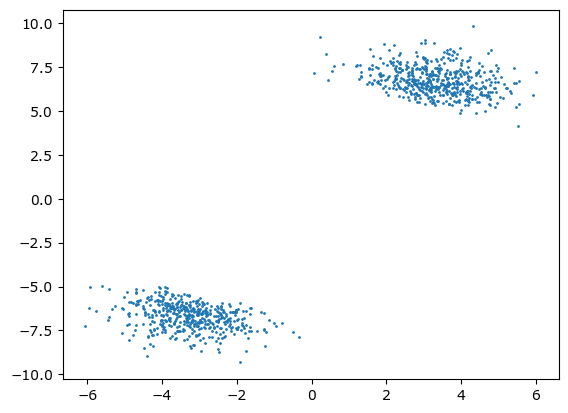

In [206]:
def sample(x_labels, y_label_dic, y):
    idx = [random.choice(y_label_dic[i]) for i in x_labels]
    return np.take(y, idx, axis=0)
sam_y = sample(x_labels, y_label_dic, y)
plt.scatter(sam_y[:,0], sam_y[:,1], s=1)

In [207]:
import torch
import torch.nn as nn

class Flow_Matching(nn.Module):
    def __init__(self, dims, nu):
        super(Flow_Matching, self).__init__()
        self.dims = dims

        blocks_v = []
        for i in range(len(dims)-1):
            blocks_v.append(nn.Linear(dims[i], dims[i+1]))
            blocks_v.append(nn.ReLU())
        blocks_v.append(nn.Linear(dims[-1], dims[0] - 1))
        self.v_net = nn.Sequential(*blocks_v)

    def forward(self, x, t):
        """
        input: [batch_size, dim + 1](x + time)
        """
        v = self.v_net(torch.concatenate([x, t], dim=-1))
        return v
    
    def sample_conditional_flow(self, x0, x1, t):
        """
        Prameters
        -------------------------------------------
        x0: [batch_size, dim] initial position
        x1: [batch_size, dim] end position
        m0: [batch_size, dim] initial mass
        m1: [batch_size, dim] end mass
        t: [batch_size] time

        Returns
        --------------------------------------------
        xts: [batch_size, dim] conditional positions
        vts: [batch_size, dim] conditional velocities
        kts: [batch_size, dim] conditional rates
        eps: [batch_size, dim] Gaussian noise for training score net
        """        
        mean = t * x1 + (1-t) * x0 # Mean for Brownian bridge
        xts = mean 
        vts = x1 - x0

        return xts, vts

    
    def sample(self, x, t, N = 1000):
        if x is None:
            x = torch.randn(self.dims[0] - 1)
        if isinstance(t, float):
            t = torch.tensor([t])
        dt = t / N

        for i in range(N):
            ipt = torch.cat([x, i * t / N], dim=-1)
            v = self.forward(x, i * t / N)
            x = x + v * dt
        
        return x


In [ ]:
torch.manual_seed(seed)
model = Flow_Matching([dim + 1, 32, 64, 32, dim + 1], nu=1)
x = torch.tensor(x, dtype=torch.float32)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
steps = 7650

for step in range(steps):
    yy = torch.tensor(sample(x_labels, y_label_dic, y), dtype=torch.float32)
    x0 = torch.tensor(x, dtype=torch.float32)
    x1 = torch.tensor(yy, dtype=torch.float32)
    t = torch.rand((batch_size, 1))
    optimizer.zero_grad()
    xts, vts = model.sample_conditional_flow(x0, x1, t)
    

    v= model.forward(xts, t)
    v_loss = torch.mean(torch.pow(v-vts, 2))
    loss = v_loss

    if step % 100 == 0:
        print(v_loss, loss)

    loss.backward()
    optimizer.step()
    

C:\Users\A\AppData\Local\Temp\ipykernel_29628\1764002850.py:11: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  x0 = torch.tensor(x, dtype=torch.float32)
C:\Users\A\AppData\Local\Temp\ipykernel_29628\1764002850.py:12: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  x1 = torch.tensor(yy, dtype=torch.float32)


tensor(22.7089, grad_fn=<MeanBackward0>) tensor(22.7089, grad_fn=<MeanBackward0>)
tensor(13.0286, grad_fn=<MeanBackward0>) tensor(13.0286, grad_fn=<MeanBackward0>)
tensor(11.0075, grad_fn=<MeanBackward0>) tensor(11.0075, grad_fn=<MeanBackward0>)
tensor(10.6564, grad_fn=<MeanBackward0>) tensor(10.6564, grad_fn=<MeanBackward0>)
tensor(9.8770, grad_fn=<MeanBackward0>) tensor(9.8770, grad_fn=<MeanBackward0>)
tensor(9.4892, grad_fn=<MeanBackward0>) tensor(9.4892, grad_fn=<MeanBackward0>)
tensor(9.0215, grad_fn=<MeanBackward0>) tensor(9.0215, grad_fn=<MeanBackward0>)
tensor(8.7672, grad_fn=<MeanBackward0>) tensor(8.7672, grad_fn=<MeanBackward0>)
tensor(8.3168, grad_fn=<MeanBackward0>) tensor(8.3168, grad_fn=<MeanBackward0>)
tensor(8.1510, grad_fn=<MeanBackward0>) tensor(8.1510, grad_fn=<MeanBackward0>)
tensor(7.7039, grad_fn=<MeanBackward0>) tensor(7.7039, grad_fn=<MeanBackward0>)
tensor(7.2919, grad_fn=<MeanBackward0>) tensor(7.2919, grad_fn=<MeanBackward0>)
tensor(7.0199, grad_fn=<MeanBack

([0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0],
 [9.865876450376946e-10,
  3.332044848542845e-08,
  7.933281519755892e-07,
  1.334574901590634e-05,
  0.00015910859015753396,
  0.0013498980316300933,
  0.008197535924596114,
  0.03593031911292576,
  0.11506967022170828,
  0.27425311775007355,
  0.5,
  0.7257468822499266,
  0.8849303297782918,
  0.9640696808870742,
  0.9918024640754038,
  0.9986501019683699,
  0.9998408914098424,
  0.9999866542509841,
  0.999999206671848,
  0.9999999666795515,
  0.9999999990134123],
 1.3699476460305906)

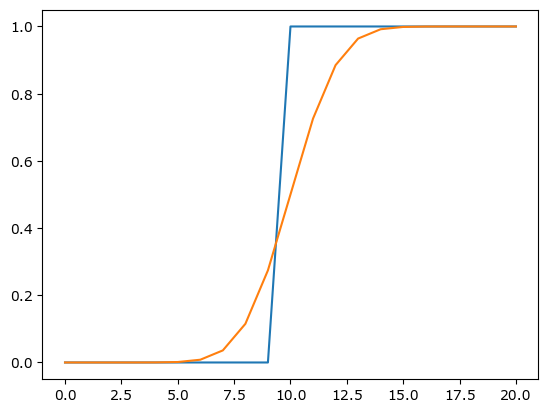

In [219]:
from scipy.stats import norm

lis = []; stand = []
for k in range(21):
    t = -1 + k / 10
    yyy = model.sample(x = t*torch.ones((batch_size, dim)), t=torch.ones((batch_size, 1)), N=1).detach()
    # yyy = toy_model.simulation(x, use_x=True).detach()

    # plt.scatter(y[:,0], y[:,1], s=1)
    # plt.scatter(yyy[:,0], yyy[:,1], s=1, alpha=0.1)
    prob = norm.sf(-t * 3 / mix)
    yyy.numpy()
    ans = (np.sign(yyy.numpy().dot([1,2])).sum() / batch_size)/2 + 0.5
    lis.append(ans)
    stand.append(prob)

plt.plot(lis)
plt.plot(stand)
lis, stand, np.sum(np.abs(np.array(lis) - np.array(stand)))

0.23836059843674084

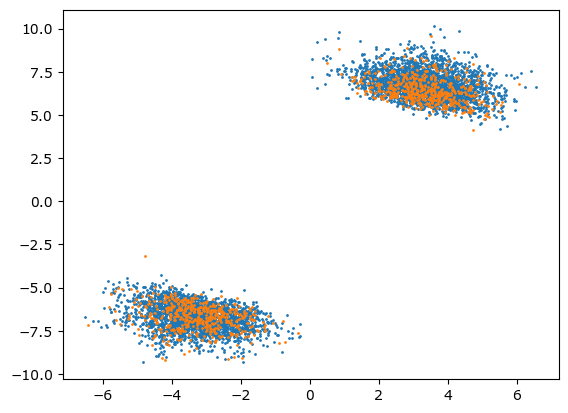

In [212]:
yyy = model.sample(x = x, t=torch.ones((batch_size, 1))).detach()
plt.scatter(y[:,0], y[:,1], s=1)
plt.scatter(yyy[:, 0], yyy[:, 1], s=1)
wasserstein(yyy, torch.tensor(y, dtype=torch.float32))